# Load Library 

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


# Load Dataset 

In [2]:
train = pd.read_csv("/kaggle/input/regipa/train_regipa.csv")
test = pd.read_csv("/kaggle/input/regipa/test_regipa.csv")

In [3]:
train = train[['Contents','District']]

In [4]:
test = test[['Contents','District']]

In [5]:
test

,Contents,District
0,এলা সবায় সবার হাতোত <> অসহায় মানুষ আচে?,Rangpur
1,কেউ কারো ইয়া নাই।,Rangpur
2,"এলা ওই যে, কাইলকা ব্যাটায় ইপতারি আনচে, খাইচোং,...",Rangpur
3,আর মুই আগোত কী করচিনু?,Rangpur
4,"<> আগের কতা বাদ দেও, এলা নাই।",Rangpur
...,...,...
8936,পরে ফ্রেডি তখন পুরা ভাইঙ্গা পরে।,Tangail
8937,আর ফ্রেডির সাথে আরো কিছু মানুষের পরিচয় হয়।,Tangail
8938,যে যারা আসলে ওই যারা এলবাম রিলিজ দেয় ওই কোম্পা...,Tangail
8939,যারা আসলে ফ্রেডির এই জনপ্রিয়তাডা আসলে তারা পছন...,Tangail


# Merge the dataset 

In [6]:
merged_df = pd.concat([train, test], ignore_index = True)

In [7]:
merged_df

,Contents,District
0,"লেখিয়্যা, কালি দিয়্যা, সেই সুন্দর করিয়া, এখন স...",Rangpur
1,"হ, একটা ফিল্ডিং গ্রুপ ছিলো।",Rangpur
2,"হ, ওরে কতা <> বুজচি বিষয়টা, ওয় তো এখনও বেরাজিল...",Rangpur
3,"সিডায়, ওই সমায় আমরা ওই কানির রুমটাত যকন আছনো এ...",Rangpur
4,"যকন কী ইয়্যা হইছিল, ওই যে সুমন আর হইলো আলম <> ...",Rangpur
...,...,...
39247,পরে ফ্রেডি তখন পুরা ভাইঙ্গা পরে।,Tangail
39248,আর ফ্রেডির সাথে আরো কিছু মানুষের পরিচয় হয়।,Tangail
39249,যে যারা আসলে ওই যারা এলবাম রিলিজ দেয় ওই কোম্পা...,Tangail
39250,যারা আসলে ফ্রেডির এই জনপ্রিয়তাডা আসলে তারা পছন...,Tangail


In [8]:
merged_df.to_csv("Dataset.csv", index = False)

# Data Analysis 

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [10]:
# Display basic info
print("Dataset Information:")
print(merged_df.info())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 39252 entries, 0 to 39251
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Contents  39252 non-null  object
 1   District  39252 non-null  object
dtypes: object(2)
memory usage: 613.4+ KB
None


In [11]:
# Check for missing values
print("\nMissing Values:")
print(merged_df.isnull().sum())


Missing Values:
Contents    0
District    0
dtype: int64


In [12]:
# Get the distribution of districts
district_counts = merged_df["District"].value_counts()
print("\nDistrict Distribution:")
print(district_counts)


District Distribution:
District
Kishoreganj    8751
Narail         7829
Tangail        6793
Narsingdi      5862
Rangpur        5255
Chittagong     4762
Name: count, dtype: int64


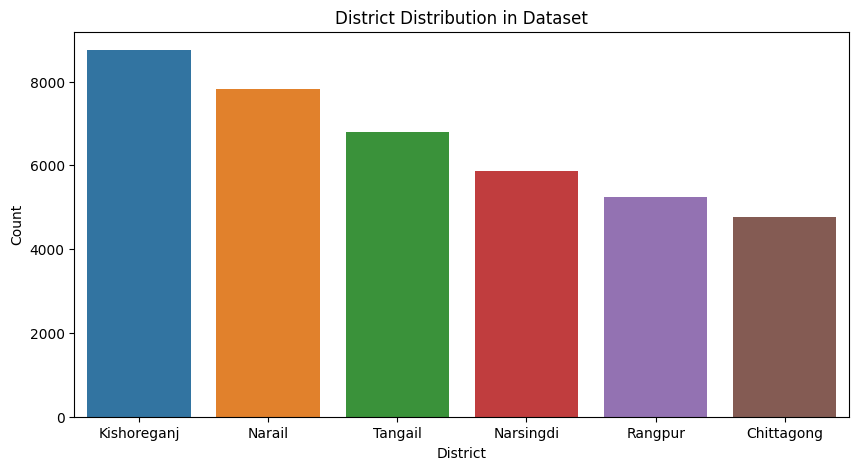

In [13]:
# Plot district distribution
plt.figure(figsize=(10, 5))
sns.barplot(x=district_counts.index, y=district_counts.values)
plt.xlabel("District")
plt.ylabel("Count")
plt.title("District Distribution in Dataset")
plt.xticks(rotation=00)
plt.show()

In [14]:
# Character count per sentence
merged_df["char_count"] = merged_df["Contents"].apply(lambda x: len(str(x)))

In [15]:
# Character count statistics
print("\nCharacter Count Statistics:")
print(merged_df["char_count"].describe())


Character Count Statistics:
count    39252.000000
mean        31.594110
std         22.660665
min          1.000000
25%         16.000000
50%         26.000000
75%         41.000000
max        306.000000
Name: char_count, dtype: float64


/usr/local/lib/python3.10/dist-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


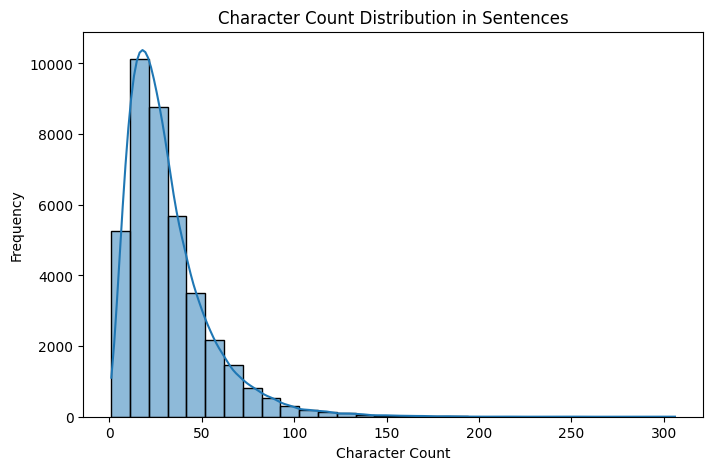

In [16]:
# Plot character count distribution
plt.figure(figsize=(8, 5))
sns.histplot(merged_df["char_count"], bins=30, kde=True)
plt.xlabel("Character Count")
plt.ylabel("Frequency")
plt.title("Character Count Distribution in Sentences")
plt.show()

# Clean the dataset 

In [17]:
import pandas as pd
import string

# Function to clean text by removing punctuation
def clean_text(text):
    if isinstance(text, str):
        return text.translate(str.maketrans("", "", string.punctuation)).strip()
    return text

# Apply cleaning function to the "Contents" column
merged_df["Contents"] = merged_df["Contents"].apply(clean_text)

# Save the cleaned dataset
merged_df.to_csv("cleaned_dataset.csv", index=False)



print("Dataset cleaned and saved as 'cleaned_dataset.csv'.")


Dataset cleaned and saved as 'cleaned_dataset.csv'.


In [18]:
merged_df

,Contents,District,char_count
0,লেখিয়্যা কালি দিয়্যা সেই সুন্দর করিয়া এখন সেই ...,Rangpur,113
1,হ একটা ফিল্ডিং গ্রুপ ছিলো।,Rangpur,27
2,হ ওরে কতা বুজচি বিষয়টা ওয় তো এখনও বেরাজিল বের...,Rangpur,70
3,সিডায় ওই সমায় আমরা ওই কানির রুমটাত যকন আছনো এক...,Rangpur,52
4,যকন কী ইয়্যা হইছিল ওই যে সুমন আর হইলো আলম জাম...,Rangpur,143
...,...,...,...
39247,পরে ফ্রেডি তখন পুরা ভাইঙ্গা পরে।,Tangail,32
39248,আর ফ্রেডির সাথে আরো কিছু মানুষের পরিচয় হয়।,Tangail,42
39249,যে যারা আসলে ওই যারা এলবাম রিলিজ দেয় ওই কোম্পা...,Tangail,60
39250,যারা আসলে ফ্রেডির এই জনপ্রিয়তাডা আসলে তারা পছন...,Tangail,57


# Split char by char 

In [19]:
import pandas as pd

# Function to split a sentence character by character with spaces
def split_chars(text):
    if isinstance(text, str):
        return " ".join(list(text))  # Splits each character with a space
    return text

# Apply the function to the "Contents" column
merged_df["Contents"] = merged_df["Contents"].apply(split_chars)

# Save the updated dataset
merged_df.to_csv("char_split_dataset.csv", index=False)


print("Character-split dataset saved as 'char_split_dataset.csv'.")


Character-split dataset saved as 'char_split_dataset.csv'.


In [20]:
merged_df

,Contents,District,char_count
0,ল ে খ ি য় ্ য া ক া ল ি দ ি য় ্ য া স ে ...,Rangpur,113
1,হ এ ক ট া ফ ি ল ্ ড ি ং গ ্ র ু প ছ ি ...,Rangpur,27
2,হ ও র ে ক ত া ব ু জ চ ি ব ি ষ য় ট া ...,Rangpur,70
3,স ি ড া য় ও ই স ম া য় আ ম র া ও ই ক ...,Rangpur,52
4,য ক ন ক ী ই য় ্ য া হ ই ছ ি ল ও ই য ...,Rangpur,143
...,...,...,...
39247,প র ে ফ ্ র ে ড ি ত খ ন প ু র া ভ া ই ...,Tangail,32
39248,আ র ফ ্ র ে ড ি র স া থ ে আ র ো ক ি ছ ...,Tangail,42
39249,য ে য া র া আ স ল ে ও ই য া র া এ ল ...,Tangail,60
39250,য া র া আ স ল ে ফ ্ র ে ড ি র এ ই জ ন ...,Tangail,57


# Apply Label Encoder 

In [21]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

# Initialize Label Encoder
label_encoder = LabelEncoder()

# Apply Label Encoding to the 'District' column
merged_df["District_Encoded"] = label_encoder.fit_transform(merged_df["District"])

# Save the updated dataset
merged_df.to_csv("encoded_dataset.csv", index=False)


# Print mapping of labels
label_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("\nLabel Encoding Mapping (District to Encoded Value):")
print(label_mapping)

print("Dataset with encoded labels saved as 'encoded_dataset.csv'.")



Label Encoding Mapping (District to Encoded Value):
{'Chittagong': 0, 'Kishoreganj': 1, 'Narail': 2, 'Narsingdi': 3, 'Rangpur': 4, 'Tangail': 5}
Dataset with encoded labels saved as 'encoded_dataset.csv'.


In [22]:
merged_df

,Contents,District,char_count,District_Encoded
0,ল ে খ ি য় ্ য া ক া ল ি দ ি য় ্ য া স ে ...,Rangpur,113,4
1,হ এ ক ট া ফ ি ল ্ ড ি ং গ ্ র ু প ছ ি ...,Rangpur,27,4
2,হ ও র ে ক ত া ব ু জ চ ি ব ি ষ য় ট া ...,Rangpur,70,4
3,স ি ড া য় ও ই স ম া য় আ ম র া ও ই ক ...,Rangpur,52,4
4,য ক ন ক ী ই য় ্ য া হ ই ছ ি ল ও ই য ...,Rangpur,143,4
...,...,...,...,...
39247,প র ে ফ ্ র ে ড ি ত খ ন প ু র া ভ া ই ...,Tangail,32,5
39248,আ র ফ ্ র ে ড ি র স া থ ে আ র ো ক ি ছ ...,Tangail,42,5
39249,য ে য া র া আ স ল ে ও ই য া র া এ ল ...,Tangail,60,5
39250,য া র া আ স ল ে ফ ্ র ে ড ি র এ ই জ ন ...,Tangail,57,5


# Apply Model 

In [23]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, GRU, Dense, Dropout

# Load the cleaned dataset
df = merged_df.copy()

# Convert text to lowercase
df["Contents"] = df["Contents"].astype(str).str.lower()

# Tokenize at the character level
tokenizer = Tokenizer(char_level=True)
tokenizer.fit_on_texts(df["Contents"])

# Convert text to sequences of character indices
sequences = tokenizer.texts_to_sequences(df["Contents"])

# Pad sequences to a fixed length
max_len = max(len(seq) for seq in sequences)
X = pad_sequences(sequences, maxlen=max_len, padding="post")

# Encode target labels (District)
label_encoder = {label: idx for idx, label in enumerate(df["District"].unique())}
df["District_Encoded"] = df["District"].map(label_encoder)

# Convert target to categorical format
y = to_categorical(df["District_Encoded"])

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


In [24]:
# Build GRU model
model = Sequential([
    Embedding(input_dim=len(tokenizer.word_index) + 1, output_dim=64, input_length=max_len),
    GRU(128, return_sequences=True),
    GRU(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(y.shape[1], activation="softmax")  # Output layer for classification
])

# Compile the model
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

# Train the model
history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_test, y_test))

# Save the trained model
model.save("gru_text_classification_model.h5")

print("Model training complete and saved as 'gru_text_classification_model.h5'.")

/usr/local/lib/python3.10/dist-packages/keras/src/layers/core/embedding.py:90: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
982/982 ━━━━━━━━━━━━━━━━━━━━ 66s 61ms/step - accuracy: 0.2168 - loss: 1.7742 - val_accuracy: 0.2229 - val_loss: 1.7699
Epoch 2/5
982/982 ━━━━━━━━━━━━━━━━━━━━ 59s 60ms/step - accuracy: 0.2195 - loss: 1.7706 - val_accuracy: 0.2229 - val_loss: 1.7689
Epoch 3/5
982/982 ━━━━━━━━━━━━━━━━━━━━ 59s 60ms/step - accuracy: 0.2248 - loss: 1.7696 - val_accuracy: 0.2229 - val_loss: 1.7690
Epoch 4/5
982/982 ━━━━━━━━━━━━━━━━━━━━ 59s 60ms/step - accuracy: 0.2236 - loss: 1.7695 - val_accuracy: 0.2229 - val_loss: 1.7690
Epoch 5/5
982/982 ━━━━━━━━━━━━━━━━━━━━ 59s 60ms/step - accuracy: 0.2216 - loss: 1.7710 - val_accuracy: 0.2229 - val_loss: 1.7689
Model training complete and saved as 'gru_text_classification_model.h5'.
